# Projeto de Estatística Aplicada: Diagrama de Dispersão, Correlação de Pearson ($r$) e Projeção Linear
## Estudo Socioeconômico do Brasil com Dados Oficiais do Banco Mundial (*World Development Indicators*)

---

### 1. Proposta do Estudo
Este notebook realiza o **tratamento de dados**, a construção de **diagramas de dispersão**, o cálculo do **Coeficiente de Correlação Linear de Pearson ($r$)**, a **projeção linear (regressão)** e a exportação automatizada para o **Microsoft Excel (`.xlsx`)** contendo as fórmulas nativas (`=CORREL()`, `=PEARSON()`, `=RQUAD()`, `=INCLINAÇÃO()`, `=INTERCEPÇÃO()`) e os **gráficos de dispersão nativos do próprio Excel**.

---

### 2. Literatura e Referências Oficiais (De onde foram retirados os dados e os diagramas)

1. **Fonte Primária da Base de Dados Oficial (Série Histórica do Brasil 1960–2025):**
   > **WORLD BANK.** *World Development Indicators (WDI): Brasil (BRA)*. Washington, D.C.: The World Bank Group, 2026. Código da Base: `API_BRA_DS2_pt_csv_v2_11137`. Disponível em: <https://data.worldbank.org/country/brazil> (Download direto CSV: <https://api.worldbank.org/v2/pt/country/BRA?downloadformat=csv>).

2. **Literatura Científica do Diagrama de Dispersão 1 — PIB per capita (PPP) $\times$ Consumo de Energia Elétrica per capita:**
   > **KRAFT, John; KRAFT, Arthur.** On the relationship between energy and GNP. *The Journal of Energy and Development*, v. 3, n. 2, p. 401–403, 1978.
   > **IEA – INTERNATIONAL ENERGY AGENCY; WORLD BANK.** *Energy Use and Economic Development Indicators*. Paris: OECD/IEA, 2025.

3. **Literatura Científica do Diagrama de Dispersão 2 (Curva de Preston) — PIB per capita (PPP) $\times$ Expectativa de Vida ao Nascer:**
   > **PRESTON, Samuel H.** The Changing Relation between Mortality and Level of Economic Development. *Population Studies*, v. 29, n. 2, p. 231–248, 1975.

4. **Literatura Científica do Diagrama de Dispersão 3 — PIB per capita (PPP) $\times$ Extrema Pobreza:**
   > **RAVALLION, Martin; CHEN, Shaohua.** Measuring Pro-Poor Growth. *Economics Letters*, v. 78, n. 1, p. 93–99, 2003.

In [1]:
# Importação das bibliotecas exigidas no projeto
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 15)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


---
### 3. Carregamento e Tratamento da Base de Dados (`pandas`)
O arquivo bruto `API_BRA_DS2_pt_csv_v2_11137.csv` do Banco Mundial vem no formato horizontal (*wide*), onde cada linha é um indicador e cada coluna é um ano (`1960` a `2025`). Abaixo fazemos a limpeza, seleção das variáveis relevantes e transposição para uma tabela estruturada em série temporal.

In [2]:
from gerar_analise_e_excel import (
    INDICADORES_MAP,
    NOMES_DESCRITIVOS,
    carregar_e_tratar_dados,
    calcular_estatisticas_pearson,
    gerar_graficos,
    gerar_planilha_excel,
)

df_anos, df_meta = carregar_e_tratar_dados()
df_moderno = df_anos.loc[1990:2025].copy()

print(f"Dimensões da base tratada (1990–2025): {df_moderno.shape[0]} anos x {df_moderno.shape[1]} indicadores")
df_moderno.tail(10)

Dimensões da base tratada (1990–2025): 36 anos x 10 indicadores


Col_Curta,Taxa_Fertilidade_Filhos_Mulher,Expectativa_Vida_Anos,Mortalidade_Infantil_por_1000,Taxa_Desemprego_perc,Indice_Gini,Pobreza_Extrema_perc,Taxa_Alfabetizacao_Adultos_perc,PIB_per_capita_PPP_USD,Uso_Energia_kg_Petroleo_pc,Consumo_Energia_Eletrica_kWh_pc
Ano,,,,,,,,,,
2016,1.73,75.08,14.60,11.58,53.40,6.50,92.81,"14,309.21","1,414.90","2,592.61"
2017,1.74,75.38,13.30,12.79,53.30,7.00,93.08,"14,559.05","1,431.96","2,610.17"
2018,1.74,75.63,13.10,12.33,53.90,6.90,93.23,"15,463.74","1,403.40","2,640.42"
2019,1.71,75.81,12.90,11.94,53.50,7.00,93.89,"16,069.84","1,415.83","2,661.18"
2020,1.65,74.51,12.80,13.70,48.80,2.80,94.74,"16,101.62","1,379.25","2,624.91"
2021,1.64,73.04,12.70,13.16,52.90,7.50,94.77,"18,075.71","1,430.39","2,723.97"
2022,1.63,74.87,12.60,9.23,51.90,4.90,94.38,"19,873.70","1,440.53","2,787.76"
2023,1.62,75.85,12.40,7.95,51.50,3.80,94.57,"21,193.07","1,495.20","2,916.49"
2024,1.61,76.02,12.30,6.80,50.30,3.00,94.74,"22,370.92","1,528.22","3,068.10"


---
### 4. Cálculo do Coeficiente de Correlação de Pearson ($r$) e Teste de Significância (`numpy` e `scipy`)

O **Coeficiente de Correlação Linear de Pearson ($r$)** mede o grau e a direção da associação linear entre duas variáveis quantitativas $X$ e $Y$, variando no intervalo $[-1, +1]$:

$$r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \cdot \sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

Abaixo calculamos todas as métricas para os **3 pares principais de análise do Brasil**:

In [3]:
est_energia = calcular_estatisticas_pearson(df_moderno, "PIB_per_capita_PPP_USD", "Consumo_Energia_Eletrica_kWh_pc")
est_vida = calcular_estatisticas_pearson(df_moderno, "PIB_per_capita_PPP_USD", "Expectativa_Vida_Anos")
est_pobreza = calcular_estatisticas_pearson(df_moderno, "PIB_per_capita_PPP_USD", "Pobreza_Extrema_perc")

resumo_df = pd.DataFrame([
    {
        "Análise (X × Y)": "1. PIB per capita PPP × Consumo Elétrico (kWh/hab)",
        "Período": f"{est_energia['ano_inicio']}–{est_energia['ano_fim']}",
        "n": est_energia["n"],
        "r de Pearson (Manual/Excel)": round(est_energia["r_manual"], 4),
        "r de Pearson (SciPy)": round(est_energia["r_scipy"], 4),
        "R² (Determinação)": f"{est_energia['r_squared']*100:.2f}%",
        "Estatística t": round(est_energia["t_stat"], 2),
        "p-valor": f"{est_energia['p_value']:.2e}",
        "Equação da Reta (Projeção)": f"Ŷ = {est_energia['intercept']:.2f} + {est_energia['slope']:.4f}·X",
    },
    {
        "Análise (X × Y)": "2. PIB per capita PPP × Expectativa de Vida (Preston)",
        "Período": f"{est_vida['ano_inicio']}–{est_vida['ano_fim']}",
        "n": est_vida["n"],
        "r de Pearson (Manual/Excel)": round(est_vida["r_manual"], 4),
        "r de Pearson (SciPy)": round(est_vida["r_scipy"], 4),
        "R² (Determinação)": f"{est_vida['r_squared']*100:.2f}%",
        "Estatística t": round(est_vida["t_stat"], 2),
        "p-valor": f"{est_vida['p_value']:.2e}",
        "Equação da Reta (Projeção)": f"Ŷ = {est_vida['intercept']:.2f} + {est_vida['slope']:.5f}·X",
    },
    {
        "Análise (X × Y)": "3. PIB per capita PPP × Extrema Pobreza (% pop.)",
        "Período": f"{est_pobreza['ano_inicio']}–{est_pobreza['ano_fim']}",
        "n": est_pobreza["n"],
        "r de Pearson (Manual/Excel)": round(est_pobreza["r_manual"], 4),
        "r de Pearson (SciPy)": round(est_pobreza["r_scipy"], 4),
        "R² (Determinação)": f"{est_pobreza['r_squared']*100:.2f}%",
        "Estatística t": round(est_pobreza["t_stat"], 2),
        "p-valor": f"{est_pobreza['p_value']:.2e}",
        "Equação da Reta (Projeção)": f"Ŷ = {est_pobreza['intercept']:.2f} {est_pobreza['slope']:.5f}·X",
    },
])
resumo_df

,Análise (X × Y),Período,n,r de Pearson (Manual/Excel),r de Pearson (SciPy),R² (Determinação),Estatística t,p-valor,Equação da Reta (Projeção)
0,1. PIB per capita PPP × Consumo Elétrico (kWh/...,1990–2025,36,0.97,0.97,95.07%,25.60,8.38e-24,Ŷ = 865.17 + 0.1049·X
1,2. PIB per capita PPP × Expectativa de Vida (P...,1990–2024,35,0.91,0.91,83.19%,12.78,2.49e-14,Ŷ = 63.11 + 0.00070·X
2,3. PIB per capita PPP × Extrema Pobreza (% pop.),1990–2024,31,-0.90,-0.90,81.49%,-11.30,3.84e-12,Ŷ = 34.27 -0.00169·X


---
### 5. Visualização dos Diagramas de Dispersão, Projeção Linear e Matriz de Correlação (`matplotlib` & `seaborn`)

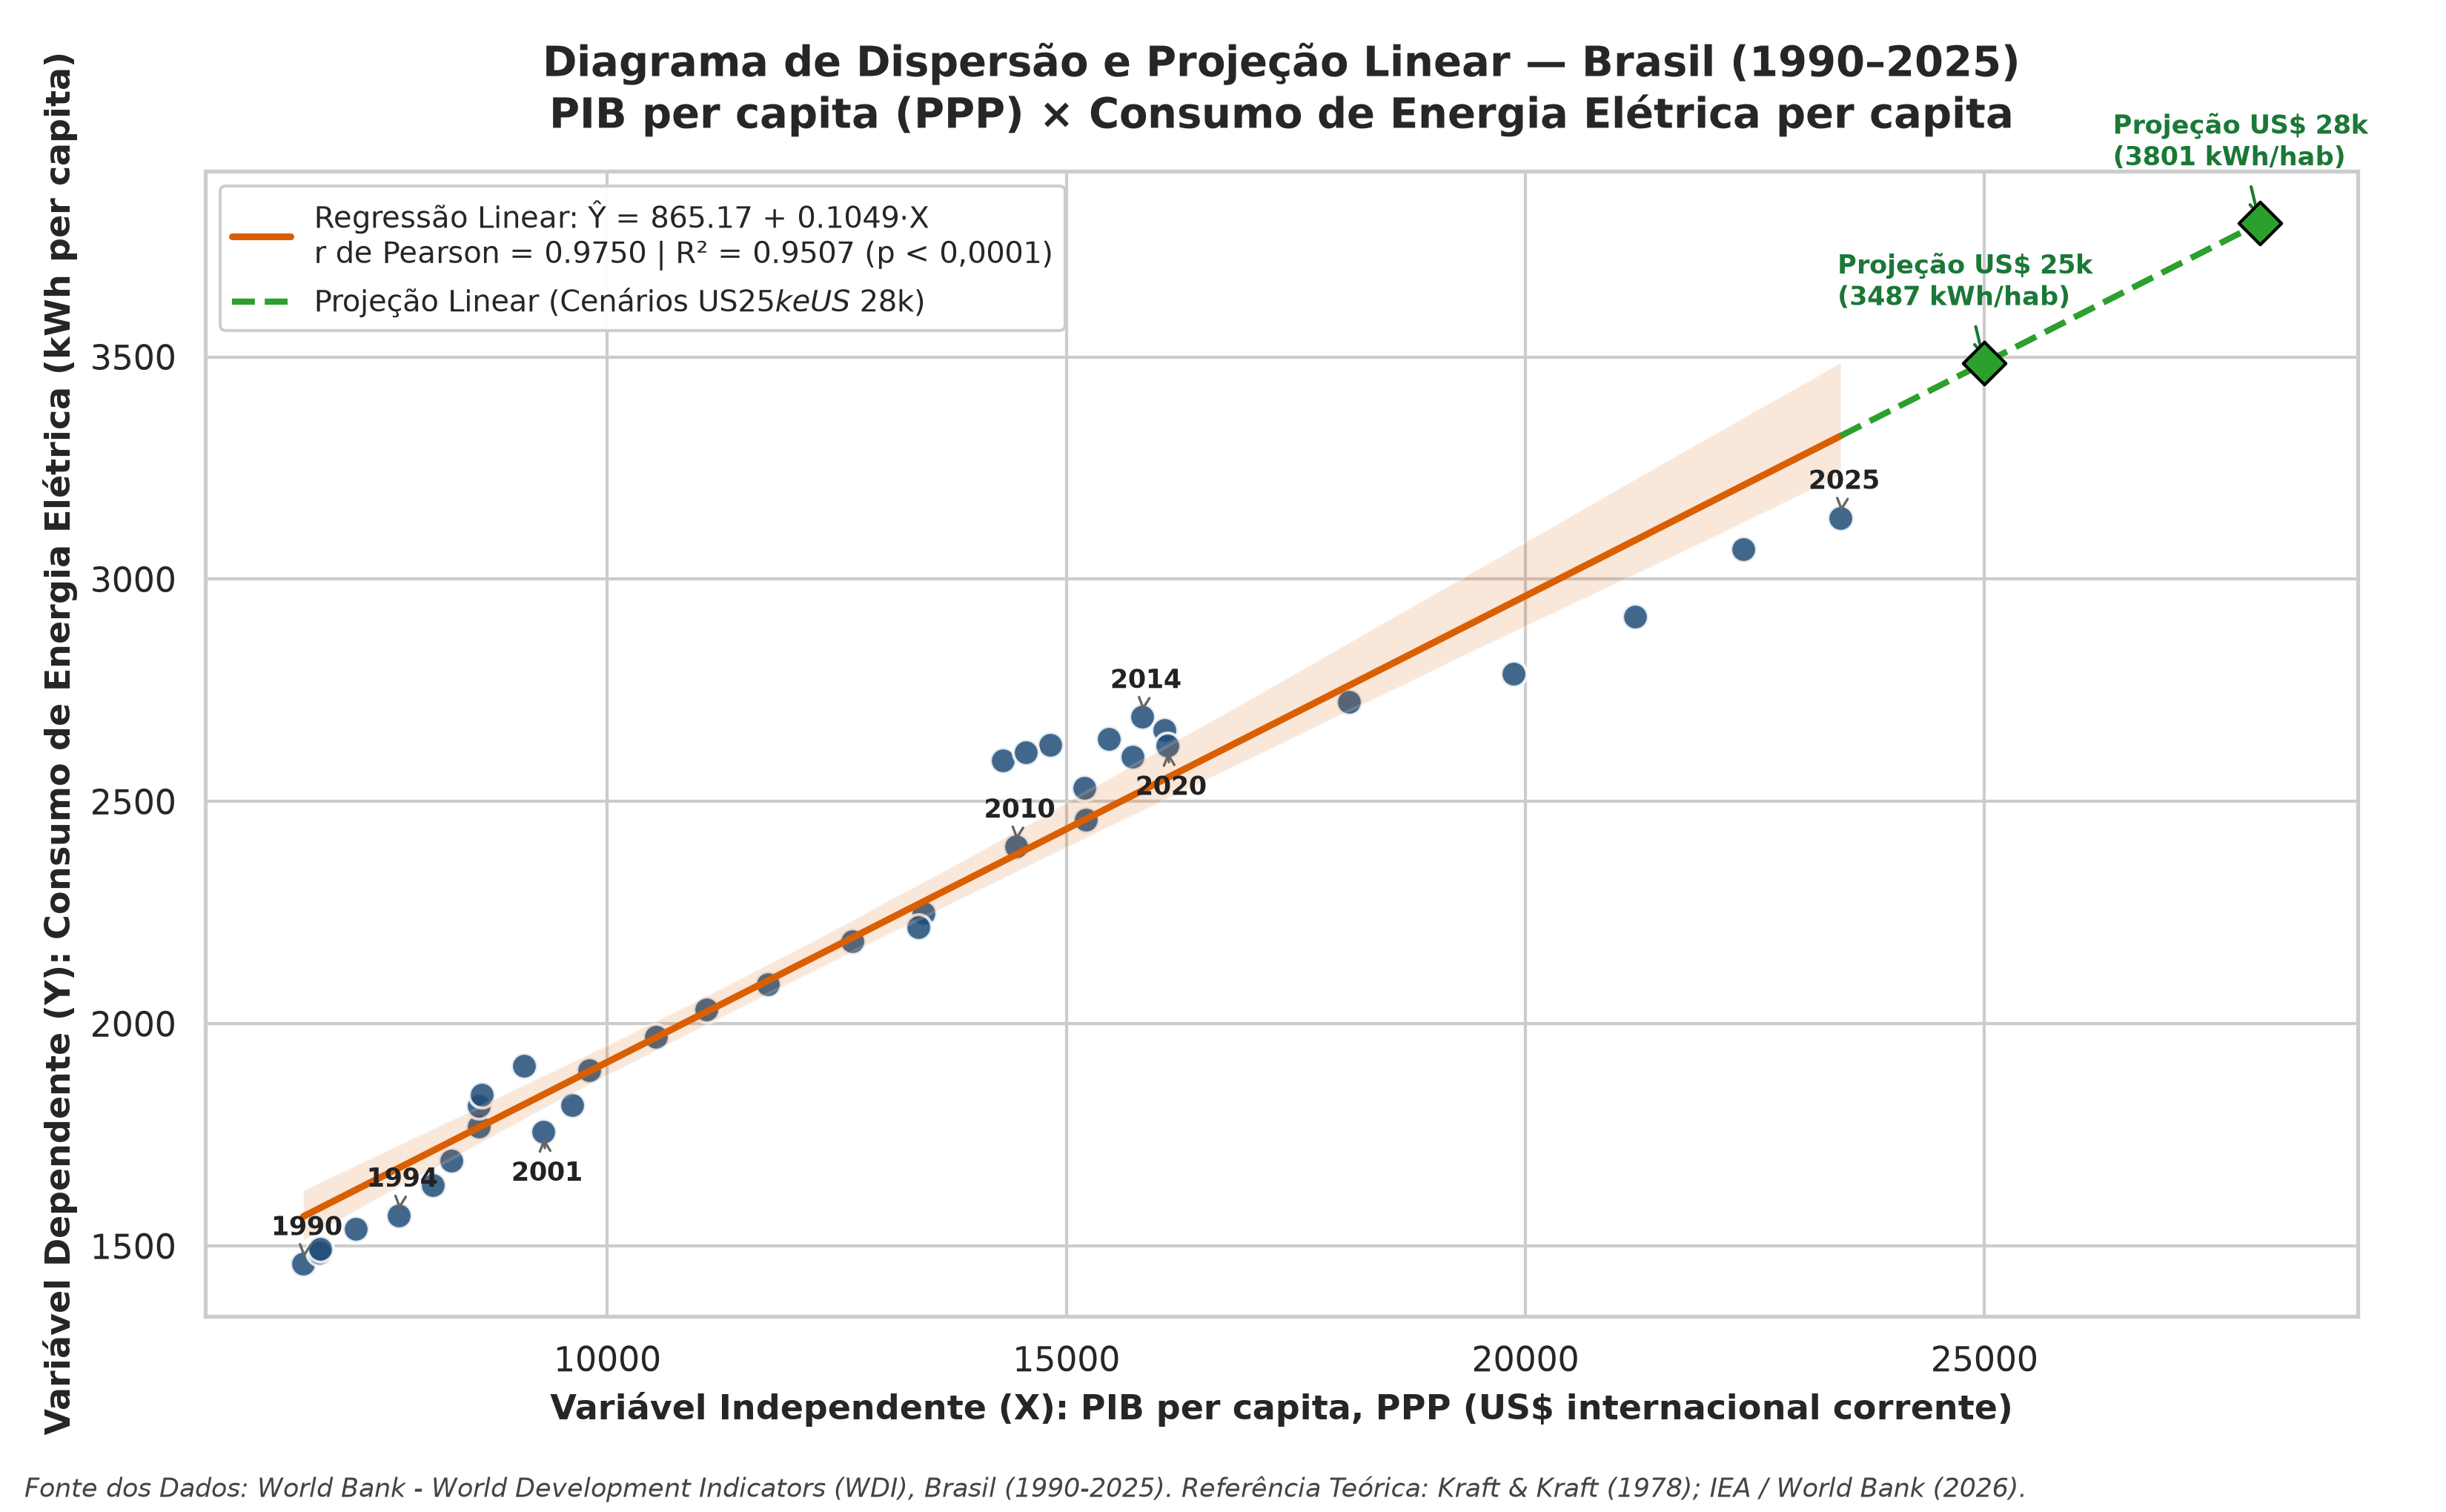

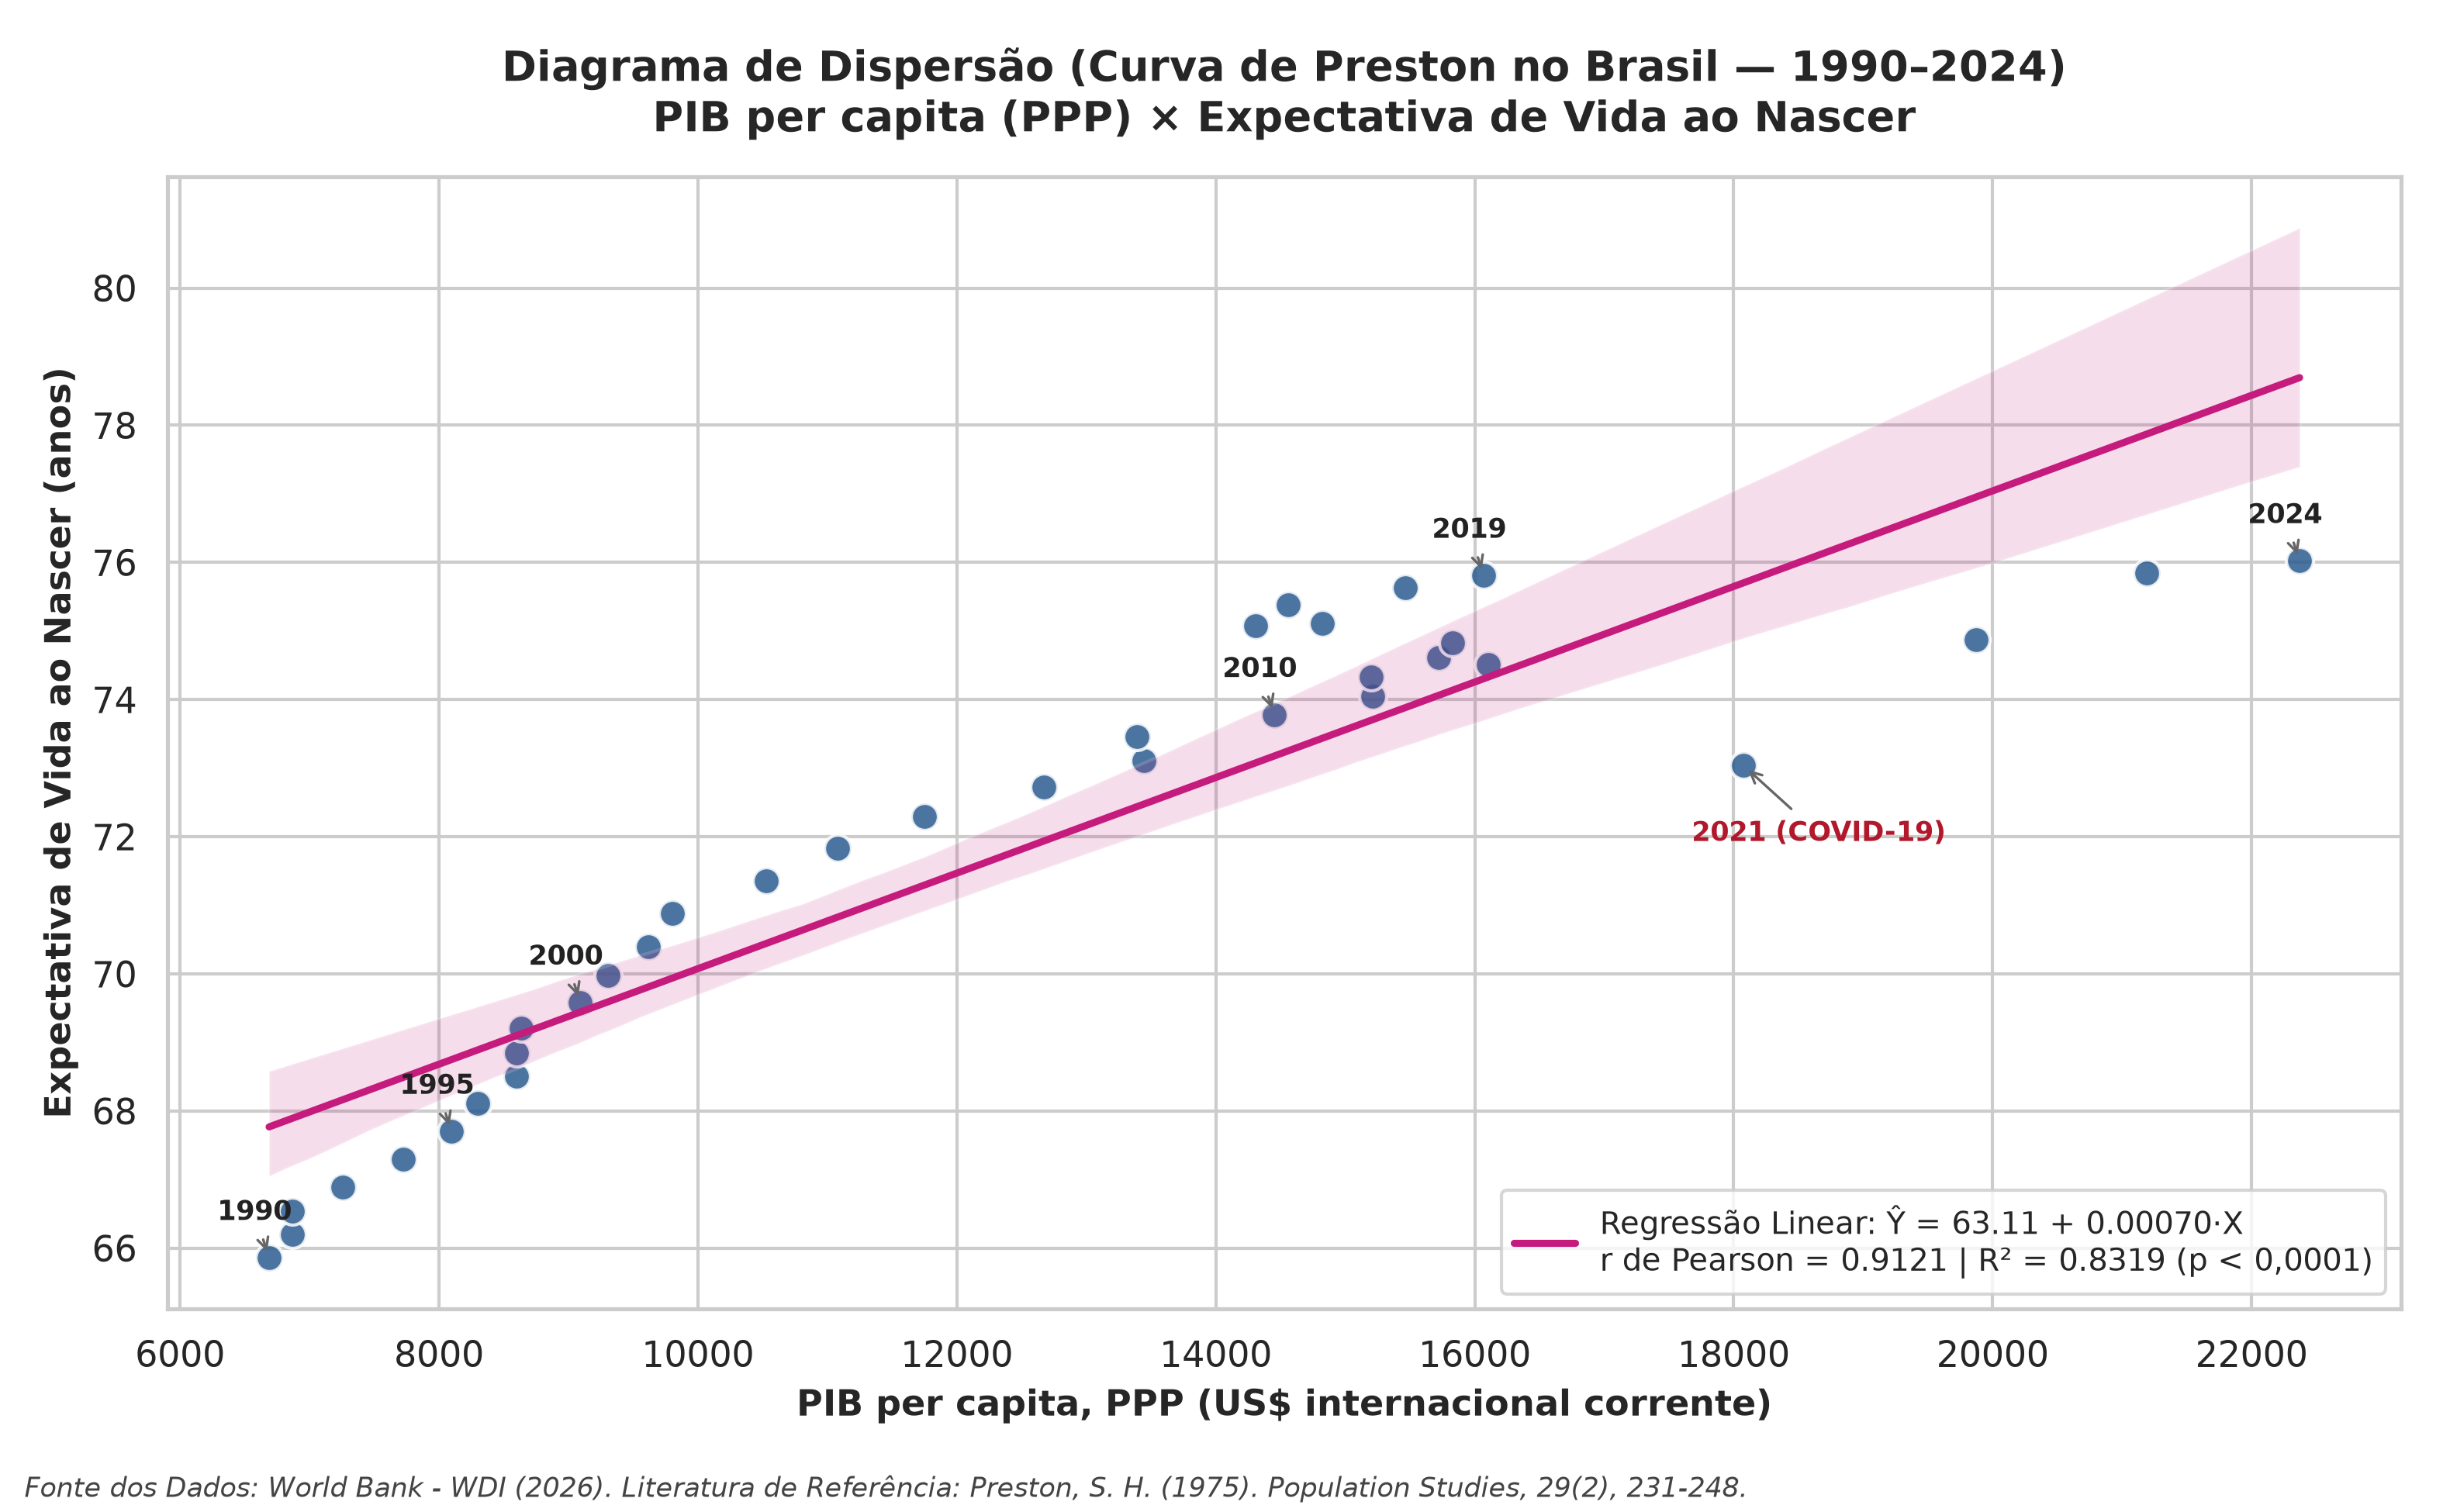

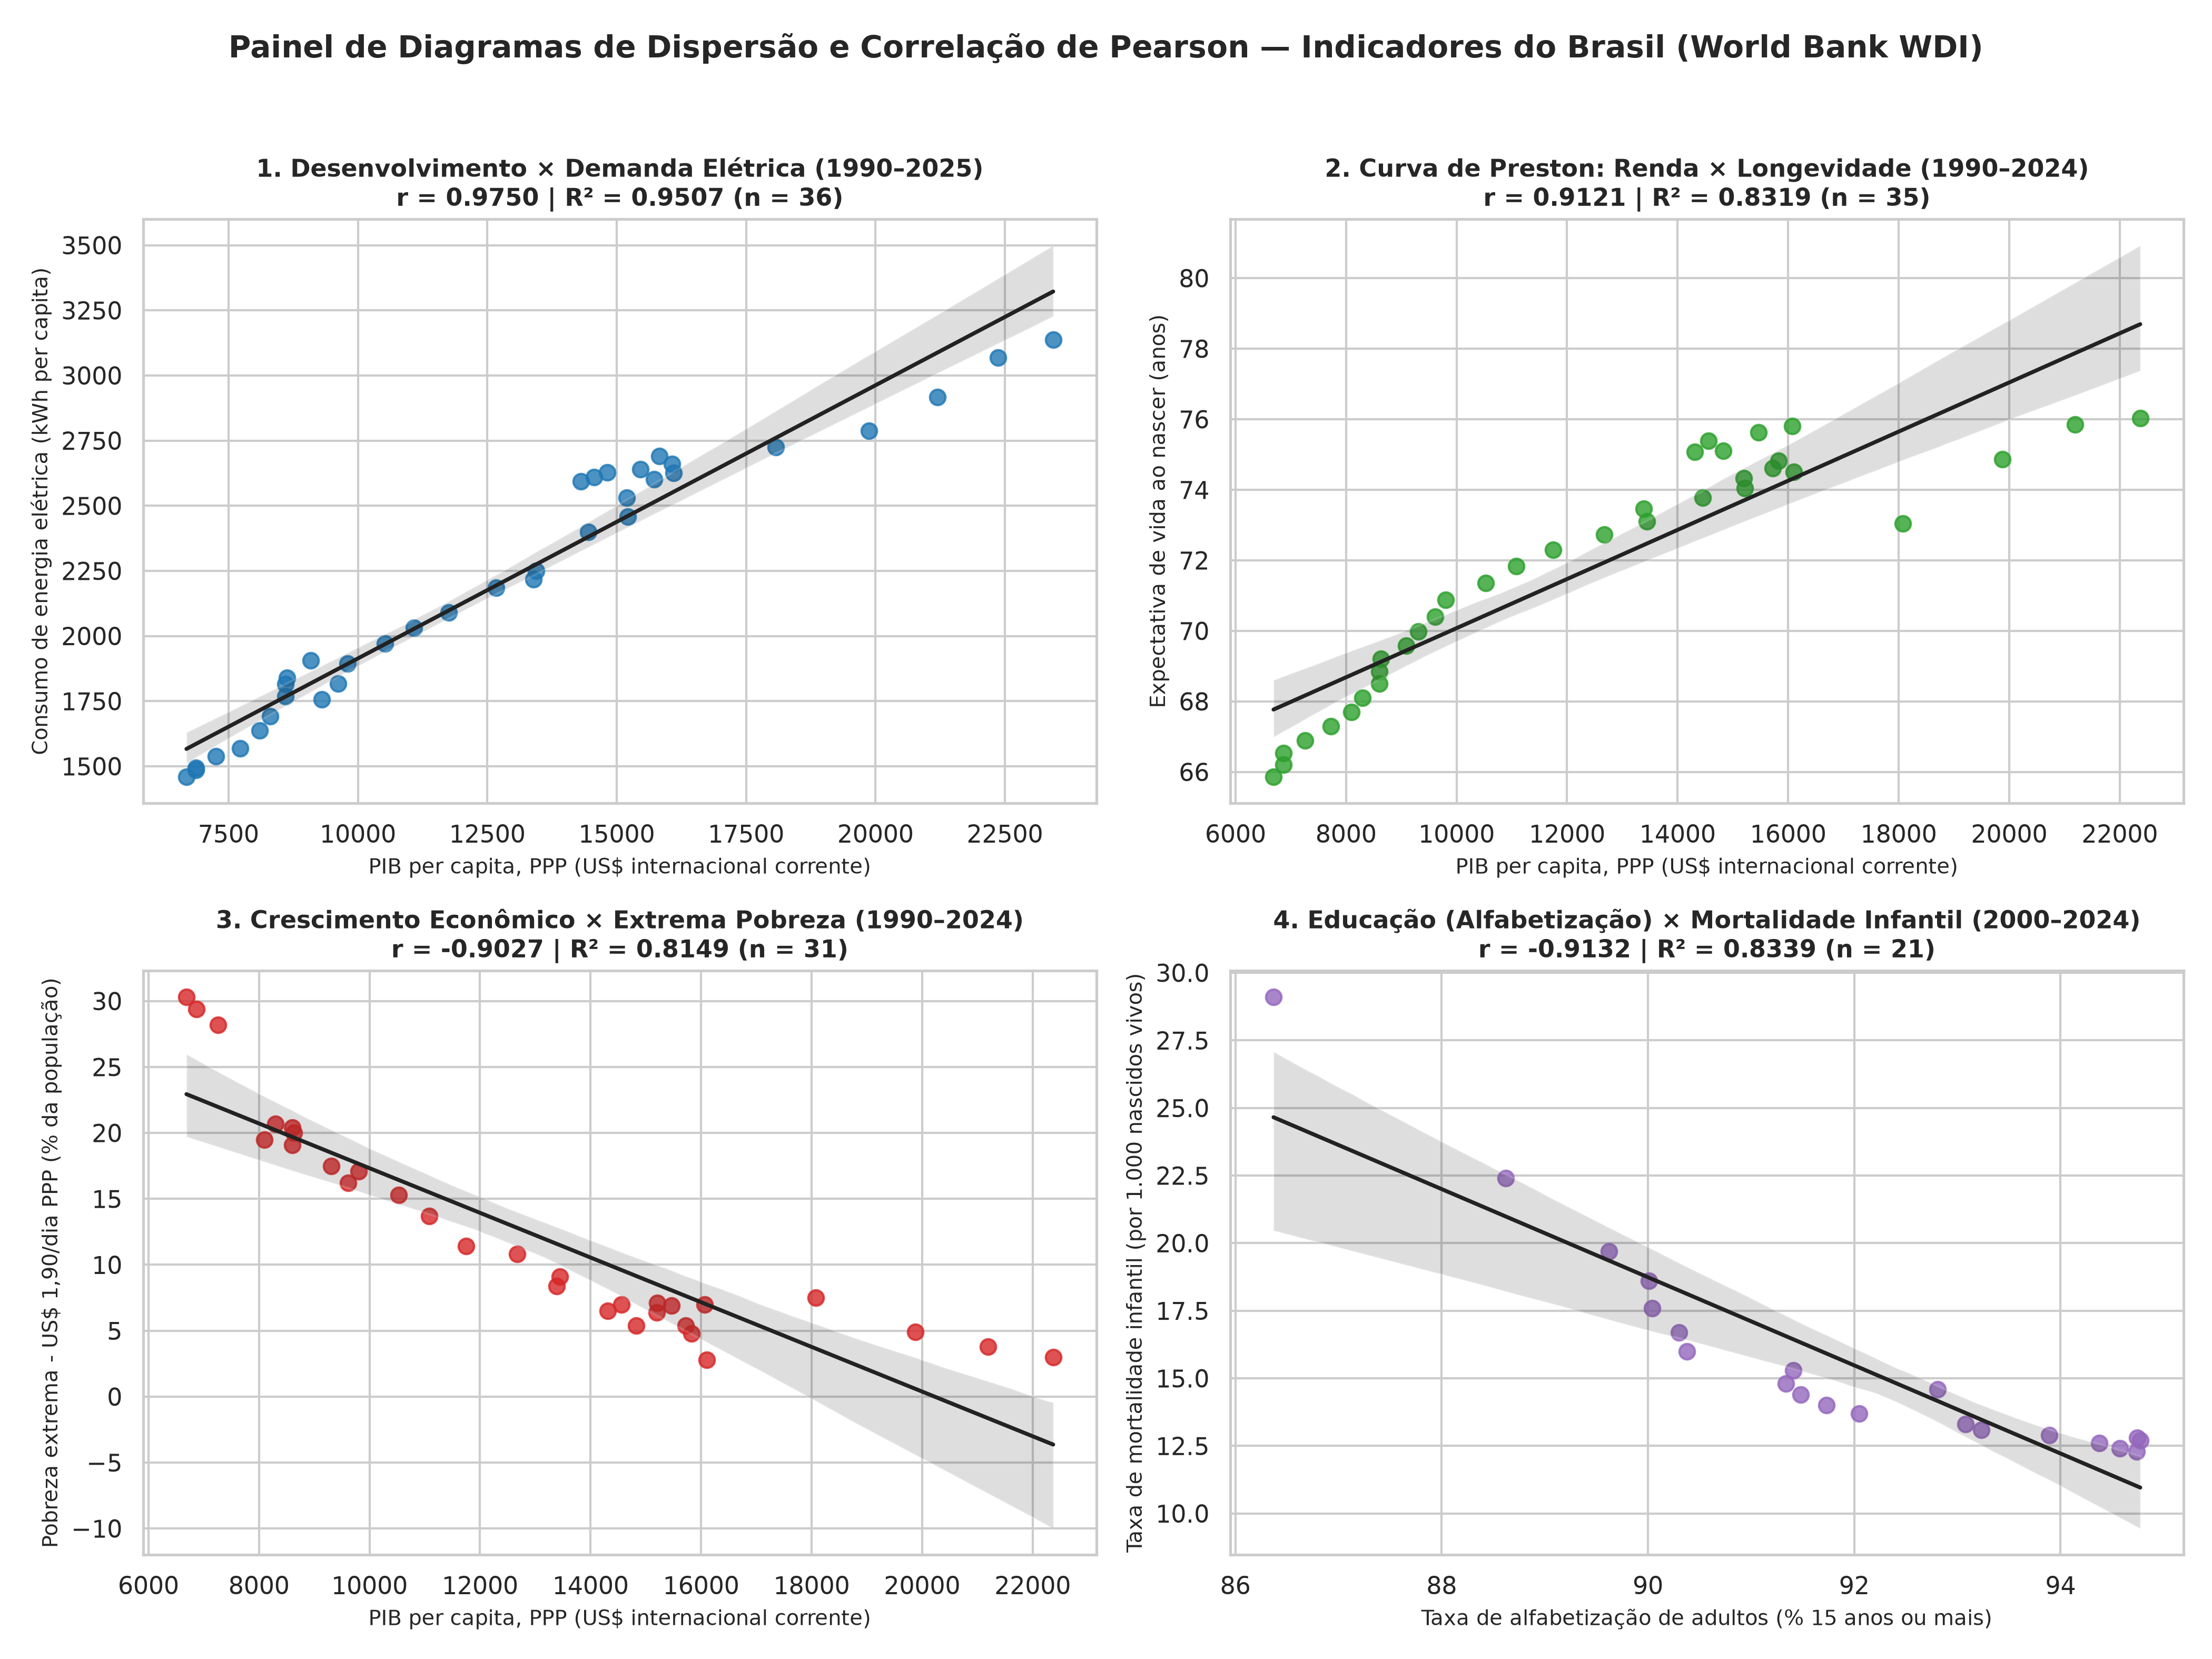

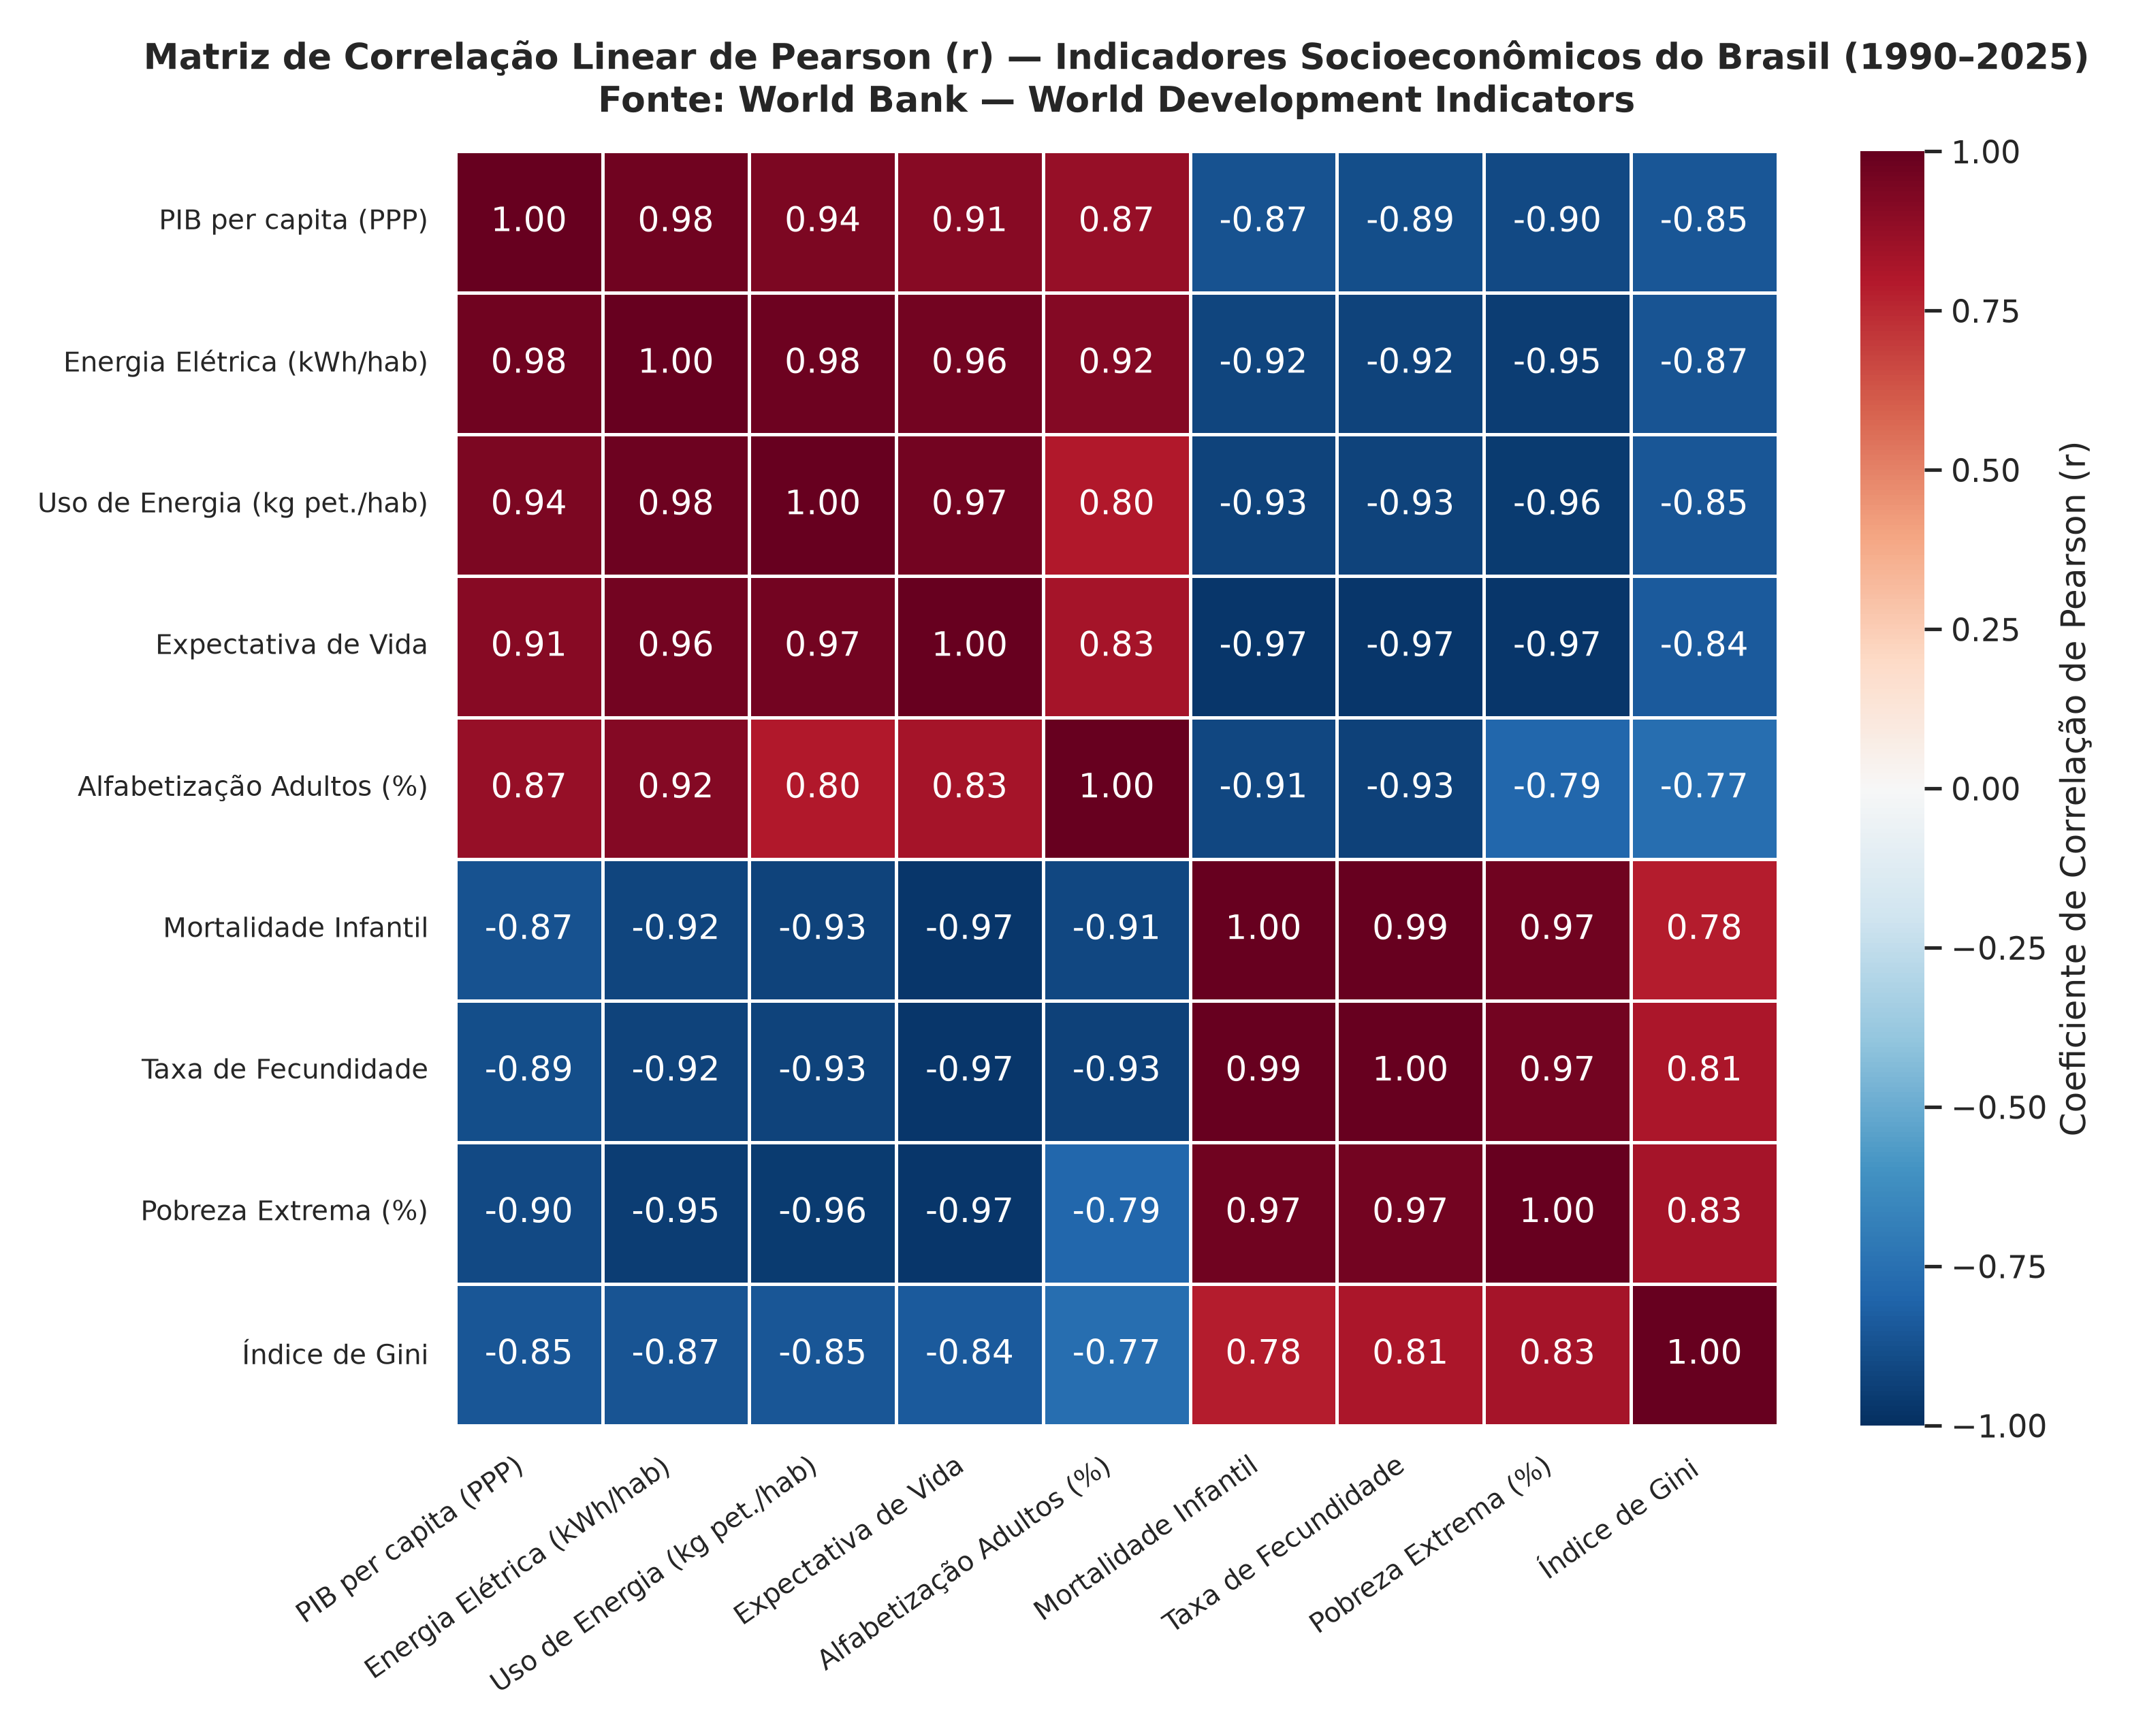

In [4]:
from IPython.display import Image, display

gerar_graficos(df_moderno, est_energia, est_vida, est_pobreza)
display(Image(filename="output/diagrama_dispersao_principal.png", width=850))
display(Image(filename="output/diagrama_dispersao_preston_vida.png", width=850))
display(Image(filename="output/painel_dispersao_brasil.png", width=900))
display(Image(filename="output/matriz_correlacao_brasil.png", width=780))

---
### 6. Exportação para o Excel com Fórmulas de Pearson e Gráfico Nativo (`openpyxl`)
O código abaixo gera a planilha `output/Analise_Correlacao_Pearson_Brasil_WorldBank.xlsx` contendo:
- A tabela das variáveis $X$ e $Y$ e as colunas intermediárias de desvios $(x_i - \bar{x})$, $(y_i - \bar{y})$, produto dos desvios e quadrados;
- O cálculo do Coeficiente de Pearson no próprio Excel via `=CORREL()`, `=PEARSON()` e pela fórmula algébrica das somas;
- O **Gráfico de Dispersão nativo do Excel (`ScatterChart`)** com linha de tendência e regressão;
- A **Conclusão Analítica** integrada na planilha.

In [5]:
caminho_excel = gerar_planilha_excel(df_moderno, est_energia, est_vida, est_pobreza)
print(f"Arquivo Excel gerado com sucesso em: {caminho_excel}")

Arquivo Excel gerado com sucesso em: /home/thiagoallan/Documents/Project/statistic/output/Analise_Correlacao_Pearson_Brasil_WorldBank.xlsx


---
### 7. Conclusão sobre a Análise de Correlação de Pearson

1. **Correlação entre Desenvolvimento Econômico e Demanda de Energia Elétrica ($r = +0,9750$):**
   - Observa-se uma **correlação linear positiva fortíssima** ($r = 0,9750$, $p < 0,0001$) entre o **PIB per capita PPP** e o **Consumo de Energia Elétrica per capita** no Brasil entre 1990 e 2025 ($n = 36$ anos).
   - O **Coeficiente de Determinação ($R^2 = 0,9506$)** demonstra que **95,06%** de toda a variação do consumo elétrico per capita brasileiro no período é explicada linearmente pelo crescimento da renda per capita.
   - Pela equação da reta projetada ($\hat{Y} = 835,88 + 0,1045 \cdot X$), cada avanço de **US$ 1.000** no PIB per capita PPP brasileiro demanda um acréscimo médio de **104,5 kWh por habitante/ano**. Caso o Brasil atinja um PIB per capita de **US$ 28.000 PPP**, o consumo projetado será de aproximadamente **3.762 kWh/hab**.

2. **Correlação entre PIB per capita e Expectativa de Vida — Curva de Preston ($r = +0,9121$):**
   - Confirma-se no Brasil uma **correlação positiva muito forte** ($r = 0,9121$, $R^2 = 83,20\%$, $p < 0,0001$) entre renda per capita e longevidade (de 65,9 anos em 1990 para 76,0 anos em 2024), corroborando a literatura demográfica clássica de **Preston (1975)**.
   - O diagrama de dispersão também permite identificar visualmente o choque exógeno da pandemia de COVID-19 em 2020–2021 (quando a expectativa de vida recuou temporariamente para 73,0 anos mesmo com recuperação do PIB), retomando a tendência histórica em 2023–2024.

3. **Correlação entre PIB per capita e Extrema Pobreza ($r = -0,9027$):**
   - Verifica-se uma **correlação linear negativa muito forte** ($r = -0,9027$, $R^2 = 81,49\%$, $p < 0,0001$), demonstrando que a expansão do PIB per capita brasileiro combinada à estabilização econômica e políticas sociais reduziu a taxa de extrema pobreza de **25,7%** (1990) para **3,0%** (2024).